In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.getOrCreate()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/14 15:39:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
from typing import Any, List, Optional, Tuple
from pyspark.sql import DataFrame, Window
from pyspark.sql import functions as F

In [3]:
data = [
    (5, 5, 181344,   7515290),
    (5, 4, 161337,   5423364),
    (5, 3, 319548,   3700403),
    (5, 2, 452825,   4909977),
    (5, 1, 1461203,  6720114),
    (5, 0, 0,              0),

    (4, 5, 64711,    4495745),
    (4, 4, 1188065,  9066067),
    (4, 3, 1677696, 14722180),
    (4, 2, 6401425, 27605785),
    (4, 1,10763213, 44461895),
    (4, 0,       0,     9052),

    (3, 5, 40517,    2458981),
    (3, 4, 788068,   8181737),
    (3, 3,2101245,  16275768),
    (3, 2,9536756,  34032015),
    (3, 1,18874024, 64400631),
    (3, 0,       0,      968),

    (2, 5, 63994,    2082020),
    (2, 4, 607937,   7706722),
    (2, 3,2093645,  14271236),
    (2, 2,6326701,  28961055),
    (2, 1,18274197, 60398807),
    (2, 0,       0,     1588),

    (1, 5, 56959,    2215100),
    (1, 4, 952746,   7931608),
    (1, 3,2059018,  17703350),
    (1, 2,3952309,  39509761),
    (1, 1,13391808, 87938607),
    (1, 0,       0,        0),

    (0, 5,      0,    308718),
    (0, 4,      0,    857035),
    (0, 3, 429189,  2867964),
    (0, 2,1018541,  4458697),
    (0, 1,6408843, 11914368),
    (0, 0,      0,        0),
]

df = spark.createDataFrame(
    data,
    ["band_1", "band_2", "saldo_over", "producao"]
)

df = (df
      .withColumn('bad_rate', F.when(F.col('producao') != 0, 100 * F.col('saldo_over') / F.col('producao')).otherwise(0))
)

df.show(36, truncate=False)

+------+------+----------+--------+------------------+
|band_1|band_2|saldo_over|producao|bad_rate          |
+------+------+----------+--------+------------------+
|5     |5     |181344    |7515290 |2.4130006959145955|
|5     |4     |161337    |5423364 |2.9748510334176355|
|5     |3     |319548    |3700403 |8.635491863994273 |
|5     |2     |452825    |4909977 |9.222548292996077 |
|5     |1     |1461203   |6720114 |21.743723395168594|
|5     |0     |0         |0       |0.0               |
|4     |5     |64711     |4495745 |1.4393832390404704|
|4     |4     |1188065   |9066067 |13.104524817652461|
|4     |3     |1677696   |14722180|11.395703625414171|
|4     |2     |6401425   |27605785|23.188708453680995|
|4     |1     |10763213  |44461895|24.207724389614974|
|4     |0     |0         |9052    |0.0               |
|3     |5     |40517     |2458981 |1.6477150494452784|
|3     |4     |788068    |8181737 |9.632037793441661 |
|3     |3     |2101245   |16275768|12.910266354251302|
|3     |2 

In [4]:
# data = [
#     ("5 - < $25k", "5 - 300–499", 24.80),
#     ("4 - $25–50k", "5 - 300–499", 22.40),
#     ("5 - < $25k", "4 - 500–599", 20.50),
#     ("3 - $50–75k", "5 - 300–499", 19.60),
#     ("4 - $25–50k", "4 - 500–599", 18.70),
#     ("2 - $75–100k", "4 - 500–599", 17.50),
#     ("2 - $75–100k", "5 - 300–499", 17.20),
#     ("3 - $50–75k", "4 - 500–599", 16.80),
#     ("5 - < $25k", "3 - 600–699", 16.20),
#     ("3 - $50–75k", "3 - 600–699", 15.50),
#     ("1 - > $100k", "5 - 300–499", 15.40),
#     ("4 - $25–50k", "3 - 600–699", 14.90),
#     ("1 - > $100k", "4 - 500–599", 12.90),
#     ("2 - $75–100k", "3 - 600–699", 12.60),
#     ("5 - < $25k", "2 - 800–850", 11.30),
#     ("4 - $25–50k", "2 - 800–850", 10.60),
#     ("1 - > $100k", "3 - 600–699", 10.30),
#     ("3 - $50–75k", "2 - 800–850", 9.20),
#     ("1 - > $100k", "2 - 800–850", 8.90),
#     ("2 - $75–100k", "2 - 800–850", 8.40),
#     ("5 - < $25k", "1 - 800–850", 8.10),
#     ("4 - $25–50k", "1 - 800–850", 7.40),
#     ("3 - $50–75k", "1 - 800–850", 6.50),
#     ("2 - $75–100k", "1 - 800–850", 5.80),
#     ("1 - > $100k", "1 - 800–850", 4.70),
# ]

# df = spark.createDataFrame(data, ["band_1", "band_2", "bad_rate"])
# df.show(1000, truncate=False)


In [5]:
list_cut_off = sorted([1, 2, 5, 8, 10, 12, 15, 18, 20])
number_of_bands = len(list_cut_off) + 1

nr_2_expr = F.lit(100).cast("int")

for cutoff in reversed(list_cut_off):
    nr_2_expr = F.when(
        F.col("bad_rate_acc") < cutoff,
        F.lit(cutoff)
    ).otherwise(nr_2_expr)

gains_input_initial = (
    df
    .withColumn('aux_NR', F.percent_rank().over(Window.partitionBy().orderBy("bad_rate")))
    .withColumn("aux_NR", F.ceil(F.col("aux_NR") * number_of_bands))
    .withColumn("aux_NR", F.when(F.col("aux_NR") == 0, 1).otherwise(F.col("aux_NR")))
    .withColumn('saldo_over_acc', F.sum(F.col('saldo_over')).over(Window.partitionBy('aux_NR').orderBy('bad_rate')))
    .withColumn('producao_acc', F.sum(F.col('producao')).over(Window.partitionBy('aux_NR').orderBy('bad_rate')))
    .withColumn('aux_bad_rate_acc', F.when(F.col('producao_acc') != 0, 100 * F.col('saldo_over_acc') / F.col('producao_acc')).otherwise(0))
    .withColumn('bad_rate_acc', F.avg(F.col('aux_bad_rate_acc')).over(Window.partitionBy('aux_NR').orderBy('bad_rate')))
    .withColumn("NR", nr_2_expr)
    .orderBy('bad_rate'))

gains_input_initial.show(1000, truncate=False)

26/11/14 15:39:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:39:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:39:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:39:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+------+------+----------+--------+------------------+------+--------------+------------+------------------+------------------+---+
|band_1|band_2|saldo_over|producao|bad_rate          |aux_NR|saldo_over_acc|producao_acc|aux_bad_rate_acc  |bad_rate_acc      |NR |
+------+------+----------+--------+------------------+------+--------------+------------+------------------+------------------+---+
|5     |0     |0         |0       |0.0               |1     |0             |1177361     |0.0               |0.0               |1  |
|4     |0     |0         |9052    |0.0               |1     |0             |1177361     |0.0               |0.0               |1  |
|3     |0     |0         |968     |0.0               |1     |0             |1177361     |0.0               |0.0               |1  |
|2     |0     |0         |1588    |0.0               |1     |0             |1177361     |0.0               |0.0               |1  |
|1     |0     |0         |0       |0.0               |1     |0             |

In [6]:

# new_gains_df = gains_input_initial

# for i in range(30):

#     old_gains_df = new_gains_df

#     new_gains_df = (
#         old_gains_df
        
#         # .withColumn('aux', F.lag('NR', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1'))))
#         # .withColumn('diff_nr_band_1',  F.lag('NR', -1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2'))) - F.col('NR').cast("int"))
#         .withColumn('diff_nr_band_1',  F.col('NR').cast("int") - F.lag('NR', 1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2'))))
#         .withColumn('diff_nr_band_2', F.col('NR').cast("int") - F.lag('NR', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1'))))
#         .withColumn('flag_inversao', F.when((F.col('diff_nr_band_1') < 0) | (F.col('diff_nr_band_2') < 0), 1).otherwise(0))

#         .withColumn('bad_rate_vizinho_band_1_direita', F.when(F.col('flag_inversao') == 1, F.lag('bad_rate', -1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
#         .withColumn('bad_rate_vizinho_band_1_esquerda', F.when(F.col('flag_inversao') == 1, F.lag('bad_rate', 1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
#         .withColumn('bad_rate_vizinho_band_1_baixo', F.when(F.col('flag_inversao') == 1, F.lag('bad_rate', -1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))
#         .withColumn('bad_rate_vizinho_band_1_cima', F.when(F.col('flag_inversao') == 1, F.lag('bad_rate', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))

#         .withColumn('flag_inversao_vizinho_band_1_direita', F.when(F.col('flag_inversao') == 1, F.lag('flag_inversao', -1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
#         .withColumn('flag_inversao_vizinho_band_1_esquerda', F.when(F.col('flag_inversao') == 1, F.lag('flag_inversao', 1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
#         .withColumn('flag_inversao_vizinho_band_1_baixo', F.when(F.col('flag_inversao') == 1, F.lag('flag_inversao', -1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))
#         .withColumn('flag_inversao_vizinho_band_1_cima', F.when(F.col('flag_inversao') == 1, F.lag('flag_inversao', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))

#         .withColumn('nr_vizinho_band_1_direita', F.when(F.col('flag_inversao_vizinho_band_1_direita') == 0, F.lag('NR', -1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
#         .withColumn('nr_vizinho_band_1_esquerda', F.when(F.col('flag_inversao_vizinho_band_1_esquerda') == 0, F.lag('NR', 1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
#         .withColumn('nr_vizinho_band_1_baixo', F.when(F.col('flag_inversao_vizinho_band_1_baixo') == 0, F.lag('NR', -1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))
#         .withColumn('nr_vizinho_band_1_cima', F.when(F.col('flag_inversao_vizinho_band_1_cima') == 0, F.lag('NR', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))

#         .withColumn('diff_bad_direita', F.when(F.col('flag_inversao_vizinho_band_1_direita') == 0, F.abs(F.col('bad_rate_vizinho_band_1_direita') - F.col('bad_rate'))).otherwise(None))
#         .withColumn('diff_bad_esquerda', F.when(F.col('flag_inversao_vizinho_band_1_esquerda') == 0, F.abs(F.col('bad_rate_vizinho_band_1_esquerda') - F.col('bad_rate'))).otherwise(None))
#         .withColumn('diff_bad_baixo', F.when(F.col('flag_inversao_vizinho_band_1_baixo') == 0, F.abs(F.col('bad_rate_vizinho_band_1_baixo') - F.col('bad_rate'))).otherwise(None))
#         .withColumn('diff_bad_cima', F.when(F.col('flag_inversao_vizinho_band_1_cima') == 0, F.abs(F.col('bad_rate_vizinho_band_1_cima') - F.col('bad_rate'))).otherwise(None))

#         .withColumn('min_diff_bad_rate', F.least(
#             F.col('diff_bad_direita'), 
#             F.col('diff_bad_esquerda'), 
#             F.col('diff_bad_baixo'), 
#             F.col('diff_bad_cima'))
#         )

#         .withColumn('NR', 
#             F.when((F.col('flag_inversao') == 1) & (F.col('min_diff_bad_rate') == F.col('diff_bad_esquerda')), F.col('nr_vizinho_band_1_esquerda'))
#             .when((F.col('flag_inversao') == 1) & (F.col('min_diff_bad_rate') == F.col('diff_bad_esquerda')), F.col('nr_vizinho_band_1_esquerda'))
#             .when((F.col('flag_inversao') == 1) & (F.col('min_diff_bad_rate') == F.col('diff_bad_baixo')), F.col('nr_vizinho_band_1_baixo'))
#             .when((F.col('flag_inversao') == 1) & (F.col('min_diff_bad_rate') == F.col('diff_bad_cima')), F.col('nr_vizinho_band_1_cima'))
#             .otherwise(F.col('NR'))
#         )
#         # .withColumn('NR', F.col('nr_ajustado'))
#     )
#     if (
#         new_gains_df.schema == old_gains_df.schema
#         and new_gains_df.exceptAll(old_gains_df).count() == 0
#         and old_gains_df.exceptAll(new_gains_df).count() == 0
#     ):
#         print(f"No changes in iteration {i+1}. Stopping the loop.")
#         break

#     print(f"Iteration {i+1} completed.")

# new_gains_df.show(1000, truncate=False)
# new_gains_df.toPandas().to_excel("nr_ajustado.xlsx", index=False)

In [7]:

new_gains_df = gains_input_initial

for i in range(5):

    old_gains_df = new_gains_df

    new_gains_df = (
        old_gains_df
        
        # .withColumn('aux', F.lag('NR', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1'))))
        # .withColumn('diff_nr_band_1',  F.lag('NR', -1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2'))) - F.col('NR').cast("int"))
        .withColumn('diff_nr_band_1',  F.col('NR').cast("int") - F.lag('NR', 1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2'))))
        .withColumn('diff_nr_band_2', F.col('NR').cast("int") - F.lag('NR', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1'))))
        .withColumn('flag_inversao', F.when((F.col('diff_nr_band_1') < 0) | (F.col('diff_nr_band_2') < 0), 1).otherwise(0))

        .withColumn('bad_rate_vizinho_band_1_direita', F.when(F.col('flag_inversao') == 1, F.lag('bad_rate', -1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
        .withColumn('bad_rate_vizinho_band_1_esquerda', F.when(F.col('flag_inversao') == 1, F.lag('bad_rate', 1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
        .withColumn('bad_rate_vizinho_band_1_baixo', F.when(F.col('flag_inversao') == 1, F.lag('bad_rate', -1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))
        .withColumn('bad_rate_vizinho_band_1_cima', F.when(F.col('flag_inversao') == 1, F.lag('bad_rate', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))

        .withColumn('flag_inversao_vizinho_band_1_direita', F.when(F.col('flag_inversao') == 1, F.lag('flag_inversao', -1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
        .withColumn('flag_inversao_vizinho_band_1_esquerda', F.when(F.col('flag_inversao') == 1, F.lag('flag_inversao', 1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
        .withColumn('flag_inversao_vizinho_band_1_baixo', F.when(F.col('flag_inversao') == 1, F.lag('flag_inversao', -1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))
        .withColumn('flag_inversao_vizinho_band_1_cima', F.when(F.col('flag_inversao') == 1, F.lag('flag_inversao', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))

        .withColumn('nr_vizinho_band_1_direita', F.when(F.col('flag_inversao_vizinho_band_1_direita') == 0, F.lag('NR', -1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
        .withColumn('nr_vizinho_band_1_esquerda', F.when(F.col('flag_inversao_vizinho_band_1_esquerda') == 0, F.lag('NR', 1).over(Window.partitionBy('band_1').orderBy(F.desc('band_1'), F.desc('band_2')))).otherwise(None))
        .withColumn('nr_vizinho_band_1_baixo', F.when(F.col('flag_inversao_vizinho_band_1_baixo') == 0, F.lag('NR', -1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))
        .withColumn('nr_vizinho_band_1_cima', F.when(F.col('flag_inversao_vizinho_band_1_cima') == 0, F.lag('NR', 1).over(Window.partitionBy('band_2').orderBy(F.desc('band_2'), F.desc('band_1')))).otherwise(None))

        .withColumn('diff_nr_direita', F.when(F.col('flag_inversao_vizinho_band_1_direita') == 0, F.col('nr_vizinho_band_1_direita') - F.col('NR')).otherwise(None)) 
        .withColumn('diff_nr_esquerda', F.when(F.col('flag_inversao_vizinho_band_1_esquerda') == 0, F.col('nr_vizinho_band_1_esquerda') - F.col('NR')).otherwise(None))
        .withColumn('diff_nr_baixo', F.when(F.col('flag_inversao_vizinho_band_1_baixo') == 0, F.col('nr_vizinho_band_1_baixo') - F.col('NR')).otherwise(None))
        .withColumn('diff_nr_cima', F.when(F.col('flag_inversao_vizinho_band_1_cima') == 0, F.col('nr_vizinho_band_1_cima') - F.col('NR')).otherwise(None))

        .withColumn('diff_bad_direita', F.when(F.col('flag_inversao_vizinho_band_1_direita') == 0, F.abs(F.col('bad_rate_vizinho_band_1_direita') - F.col('bad_rate'))).otherwise(None))
        .withColumn('diff_bad_esquerda', F.when(F.col('flag_inversao_vizinho_band_1_esquerda') == 0, F.abs(F.col('bad_rate_vizinho_band_1_esquerda') - F.col('bad_rate'))).otherwise(None))
        .withColumn('diff_bad_baixo', F.when(F.col('flag_inversao_vizinho_band_1_baixo') == 0, F.abs(F.col('bad_rate_vizinho_band_1_baixo') - F.col('bad_rate'))).otherwise(None))
        .withColumn('diff_bad_cima', F.when(F.col('flag_inversao_vizinho_band_1_cima') == 0, F.abs(F.col('bad_rate_vizinho_band_1_cima') - F.col('bad_rate'))).otherwise(None))

        .withColumn('min_diff_nr', F.least(
            F.when(F.col('diff_nr_direita') >= 0, F.col('diff_nr_direita')).otherwise(None), # ideal >=0 
            F.when(F.col('diff_nr_esquerda') <= 0, F.col('diff_nr_esquerda')).otherwise(None), # ideal <=0
            F.when(F.col('diff_nr_baixo') >= 0, F.col('diff_nr_baixo')).otherwise(None), # ideal >=0
            F.when(F.col('diff_nr_cima') <= 0, F.col('diff_nr_cima')).otherwise(None))) # ideal <= 0

        .withColumn('min_diff_bad_rate', F.least(
            F.col('diff_bad_direita'), 
            F.col('diff_bad_esquerda'), 
            F.col('diff_bad_baixo'), 
            F.col('diff_bad_cima'))
        )

        .withColumn('NR', 
            F.when((F.col('flag_inversao') == 1) & (F.col('min_diff_bad_rate') == F.col('diff_bad_esquerda')), F.col('nr_vizinho_band_1_esquerda'))
            .when((F.col('flag_inversao') == 1) & (F.col('min_diff_bad_rate') == F.col('diff_bad_esquerda')), F.col('nr_vizinho_band_1_esquerda'))
            .when((F.col('flag_inversao') == 1) & (F.col('min_diff_bad_rate') == F.col('diff_bad_baixo')), F.col('nr_vizinho_band_1_baixo'))
            .when((F.col('flag_inversao') == 1) & (F.col('min_diff_bad_rate') == F.col('diff_bad_cima')), F.col('nr_vizinho_band_1_cima'))
            .otherwise(F.col('NR'))
        )

        # .withColumn('NR', 
        #     F.when((F.col('flag_inversao') == 1) & (F.col('min_diff_nr') == F.col('diff_nr_esquerda')), F.col('nr_vizinho_band_1_esquerda'))
        #     .when((F.col('flag_inversao') == 1) & (F.col('min_diff_nr') == F.col('diff_nr_esquerda')), F.col('nr_vizinho_band_1_esquerda'))
        #     .when((F.col('flag_inversao') == 1) & (F.col('min_diff_nr') == F.col('diff_nr_baixo')), F.col('nr_vizinho_band_1_baixo'))
        #     .when((F.col('flag_inversao') == 1) & (F.col('min_diff_nr') == F.col('diff_nr_cima')), F.col('nr_vizinho_band_1_cima'))
        #     .otherwise(F.col('NR'))
        # )

        .withColumn('saldo_over_acc', F.sum(F.col('saldo_over')).over(Window.partitionBy('NR').orderBy('bad_rate')))
        .withColumn('producao_acc', F.sum(F.col('producao')).over(Window.partitionBy('NR').orderBy('bad_rate')))
        .withColumn('bad_rate_acc', 100 * (F.col('saldo_over_acc') / F.col('producao_acc')))
        # .withColumn("NR", nr_2_expr)

    )
    if (
        new_gains_df.schema == old_gains_df.schema
        and new_gains_df.exceptAll(old_gains_df).count() == 0
        and old_gains_df.exceptAll(new_gains_df).count() == 0
    ):
        print(f"No changes in iteration {i+1}. Stopping the loop.")
        break

    print(f"Iteration {i+1} completed.")

new_gains_df.show(1000, truncate=False)
new_gains_df.toPandas().to_excel("nr_ajustado.xlsx", index=False)

Iteration 1 completed.


26/11/14 15:39:56 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:39:56 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:39:56 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:39:56 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:39:56 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/11/14 15:39:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance

Iteration 2 completed.


26/11/14 15:40:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 1

Iteration 3 completed.


26/11/14 15:40:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 1

No changes in iteration 4. Stopping the loop.


26/11/14 15:40:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+------+------+----------+--------+------------------+------+--------------+------------+------------------+------------------+---+--------------+--------------+-------------+-------------------------------+--------------------------------+-----------------------------+----------------------------+------------------------------------+-------------------------------------+----------------------------------+---------------------------------+-------------------------+--------------------------+-----------------------+----------------------+---------------+----------------+-------------+------------+------------------+-------------------+------------------+------------------+-----------+-------------------+
|band_1|band_2|saldo_over|producao|bad_rate          |aux_NR|saldo_over_acc|producao_acc|aux_bad_rate_acc  |bad_rate_acc      |NR |diff_nr_band_1|diff_nr_band_2|flag_inversao|bad_rate_vizinho_band_1_direita|bad_rate_vizinho_band_1_esquerda|bad_rate_vizinho_band_1_baixo|bad_rate_vizinho_

26/11/14 15:40:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/14 15:40:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


In [15]:
# Assign monotone NR labels with cutoff-valid weighted group bad rates.
# NR labels 1, 2, ..., 20 represent upper bounds; 100 is the >20% overflow label.
# For each NR, its weighted rate is constrained to (previous cutoff, NR] (first bucket: <=1).

import numpy as np
import pandas as pd
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import lil_matrix

cutoffs = sorted([1, 2, 5, 8, 10, 12, 15, 18, 20])
nr_labels = cutoffs + [100]
n_labels = len(nr_labels)

cells_pdf = df.select("band_1", "band_2", "saldo_over", "producao").toPandas()
cells_pdf = cells_pdf.sort_values(["band_1", "band_2"], ascending=[False, False]).reset_index(drop=True)

n_cells = len(cells_pdf)
var_count = n_cells * n_labels
cell_idx = {
    (int(row.band_1), int(row.band_2)): i
    for i, row in cells_pdf.iterrows()
}
band1_order = sorted(cells_pdf["band_1"].unique(), reverse=True)
band2_order = sorted(cells_pdf["band_2"].unique(), reverse=True)

constraint_rows = []
constraint_lbs = []
constraint_ubs = []

def add_constraint(coefficients, lb=-np.inf, ub=np.inf):
    constraint_rows.append(coefficients)
    constraint_lbs.append(lb)
    constraint_ubs.append(ub)

# Exactly one NR label per cell.
for i in range(n_cells):
    add_constraint({i * n_labels + k: 1.0 for k in range(n_labels)}, lb=1.0, ub=1.0)

# Moving to a lower band_1 or band_2 value cannot lower NR.
for (band1, band2), i in cell_idx.items():
    pos1 = band1_order.index(band1)
    pos2 = band2_order.index(band2)
    neighbors = []
    if pos1 + 1 < len(band1_order):
        neighbors.append((band1_order[pos1 + 1], band2))
    if pos2 + 1 < len(band2_order):
        neighbors.append((band1, band2_order[pos2 + 1]))
    for neighbor in neighbors:
        if neighbor in cell_idx:
            j = cell_idx[neighbor]
            coefficients = {i * n_labels + k: float(-k) for k in range(n_labels)}
            coefficients.update({j * n_labels + k: float(k) for k in range(n_labels)})
            add_constraint(coefficients, lb=0.0)

bad = cells_pdf["saldo_over"].to_numpy(dtype=float)
exposure = cells_pdf["producao"].to_numpy(dtype=float)
lower_cutoffs = [0.0] + cutoffs

# The weighted rate of each nonempty NR group must be in its cutoff interval.
for k, label in enumerate(nr_labels):
    lower_fraction = lower_cutoffs[k] / 100.0
    lower_coeffs = {
        i * n_labels + k: float(bad[i] - lower_fraction * exposure[i])
        for i in range(n_cells)
    }
    add_constraint(lower_coeffs, lb=0.0)

    if k < len(cutoffs):
        upper_fraction = cutoffs[k] / 100.0
        upper_coeffs = {
            i * n_labels + k: float(bad[i] - upper_fraction * exposure[i])
            for i in range(n_cells)
        }
        add_constraint(upper_coeffs, ub=0.0)

# Minimize exposure-weighted squared distance to each bucket midpoint.
bucket_centers = [(lower_cutoffs[k] + label) / 2.0 for k, label in enumerate(cutoffs)]
bucket_centers.append(20.0)  # overflow bucket (>20%)
cost = np.zeros(var_count, dtype=float)

for i in range(n_cells):
    if exposure[i] > 0:
        cell_rate = 100.0 * bad[i] / exposure[i]
        for k, center in enumerate(bucket_centers):
            cost[i * n_labels + k] = exposure[i] * (cell_rate - center) ** 2
    else:
        # No observed rate: choose the lowest label allowed by monotonicity.
        for k in range(n_labels):
            cost[i * n_labels + k] = k * 1e-6

A = lil_matrix((len(constraint_rows), var_count), dtype=float)
for row_idx, coefficients in enumerate(constraint_rows):
    for col_idx, value in coefficients.items():
        A[row_idx, col_idx] = value

solution = milp(
    c=cost,
    integrality=np.ones(var_count),
    bounds=Bounds(np.zeros(var_count), np.ones(var_count)),
    constraints=LinearConstraint(A.tocsr(), np.asarray(constraint_lbs), np.asarray(constraint_ubs)),
    options={"time_limit": 60},
)

if not solution.success:
    raise RuntimeError(f"Could not find a cutoff-valid monotone NR assignment: {solution.message}")

chosen_labels = np.argmax(solution.x.reshape(n_cells, n_labels), axis=1)
cells_pdf["NR"] = [nr_labels[k] for k in chosen_labels]

nr_assignments = spark.createDataFrame(cells_pdf[["band_1", "band_2", "NR"]])
new_gains_df = df.join(nr_assignments, ["band_1", "band_2"], "left")

nr_weighted_rates = (
    new_gains_df
    .groupBy("NR")
    .agg(
        F.sum("saldo_over").alias("nr_saldo_over"),
        F.sum("producao").alias("nr_producao"),
    )
    .withColumn(
        "nr_weighted_bad_rate",
        F.when(F.col("nr_producao") > 0,
               100.0 * F.col("nr_saldo_over") / F.col("nr_producao"))
    )
    .orderBy("NR")
)

new_gains_df = new_gains_df.join(
    nr_weighted_rates.select("NR", "nr_weighted_bad_rate"),
    "NR",
    "left",
)

nr_weighted_rates.show(truncate=False)
new_gains_df.orderBy(F.desc("band_1"), F.desc("band_2")).show(100, truncate=False)


+---+-------------+-----------+--------------------+
|NR |nr_saldo_over|nr_producao|nr_weighted_bad_rate|
+---+-------------+-----------+--------------------+
|2  |286572       |14470016   |1.9804539262430672  |
|5  |282290       |10029202   |2.81468056980007    |
|10 |772373       |8610380    |8.970254506769736   |
|12 |5214512      |48465349   |10.759258124809955  |
|15 |6683097      |51118318   |13.073781105239027  |
|100|96409020     |410413343  |23.49071287382584   |
+---+-------------+-----------+--------------------+



+---+------+------+----------+--------+------------------+--------------------+
|NR |band_1|band_2|saldo_over|producao|bad_rate          |nr_weighted_bad_rate|
+---+------+------+----------+--------+------------------+--------------------+
|2  |5     |5     |181344    |7515290 |2.4130006959145955|1.9804539262430672  |
|5  |5     |4     |161337    |5423364 |2.9748510334176355|2.81468056980007    |
|10 |5     |3     |319548    |3700403 |8.635491863994273 |8.970254506769736   |
|10 |5     |2     |452825    |4909977 |9.222548292996077 |8.970254506769736   |
|100|5     |1     |1461203   |6720114 |21.743723395168594|23.49071287382584   |
|100|5     |0     |0         |0       |0.0               |23.49071287382584   |
|2  |4     |5     |64711     |4495745 |1.4393832390404704|1.9804539262430672  |
|12 |4     |4     |1188065   |9066067 |13.104524817652461|10.759258124809955  |
|12 |4     |3     |1677696   |14722180|11.395703625414171|10.759258124809955  |
|100|4     |2     |6401425   |27605785|2

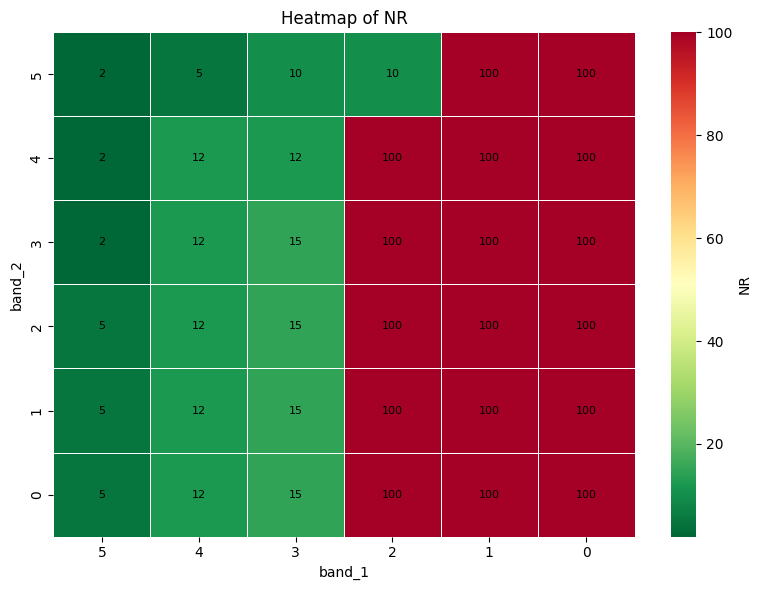

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_df = (
    new_gains_df
    .select("band_1", "band_2", "NR")
    .toPandas()
    .pivot(index="band_1", columns="band_2", values="NR")
    .sort_index(ascending=False)
    .sort_index(axis=1, ascending=False)
)

plt.figure(figsize=(max(8, heatmap_df.shape[1] * 0.8), max(6, heatmap_df.shape[0] * 0.65)))
ax = sns.heatmap(
    heatmap_df,
    mask=heatmap_df.isna(),
    cmap="RdYlGn_r",
    annot=False,
    linewidths=0.5,
    cbar_kws={"label": "NR"}
)

# Add labels ourselves so missing pivot combinations are shown as NULL.
for row_idx, (_, row) in enumerate(heatmap_df.iterrows()):
    for col_idx, value in enumerate(row):
        label = "NULL" if pd.isna(value) else f"{value:.0f}"
        ax.text(col_idx + 0.5, row_idx + 0.5, label,
                ha="center", va="center", fontsize=8, color="black")

plt.title("Heatmap of NR")
plt.xlabel("band_1")
plt.ylabel("band_2")
plt.tight_layout()
plt.show()

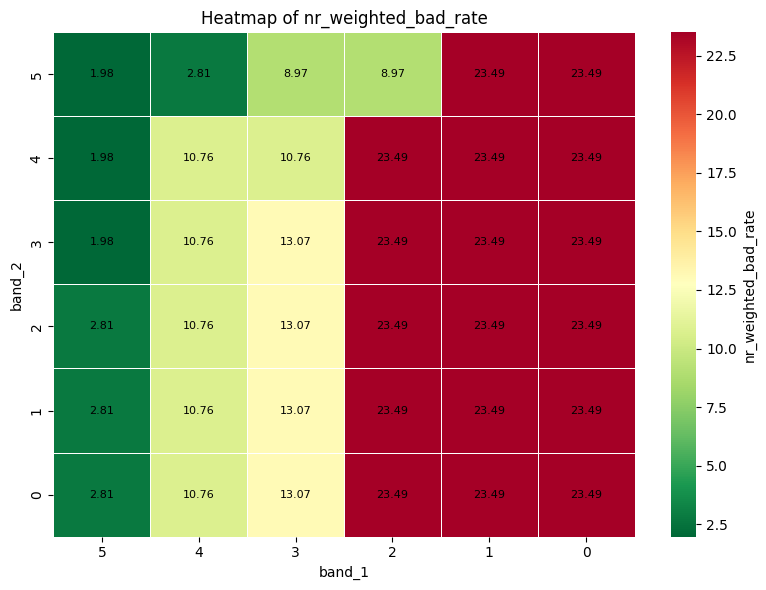

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_df = (
    new_gains_df
    .select("band_1", "band_2", "nr_weighted_bad_rate")
    .toPandas()
    .pivot(index="band_1", columns="band_2", values="nr_weighted_bad_rate")
    .sort_index(ascending=False)
    .sort_index(axis=1, ascending=False)
)

plt.figure(figsize=(max(8, heatmap_df.shape[1] * 0.8), max(6, heatmap_df.shape[0] * 0.65)))
ax = sns.heatmap(
    heatmap_df,
    mask=heatmap_df.isna(),
    cmap="RdYlGn_r",
    annot=False,
    linewidths=0.5,
    cbar_kws={"label": "nr_weighted_bad_rate"}
)

# Add labels ourselves so missing pivot combinations are shown as NULL.
for row_idx, (_, row) in enumerate(heatmap_df.iterrows()):
    for col_idx, value in enumerate(row):
        label = "NULL" if pd.isna(value) else f"{value:.2f}"
        ax.text(col_idx + 0.5, row_idx + 0.5, label,
                ha="center", va="center", fontsize=8, color="black")

plt.title("Heatmap of nr_weighted_bad_rate")
plt.xlabel("band_1")
plt.ylabel("band_2")
plt.tight_layout()
plt.show()

In [19]:
# Alternative: monotone NR labels with running weighted bad rates.
# Cells are ordered within each NR by bad_rate ascending, then band_1/band_2 descending.
# Because strict cutoff constraints can conflict with the monotone grid, this model
# minimizes cutoff violations and reports the remaining total normalized slack.

import numpy as np
import pandas as pd
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import lil_matrix

running_cutoffs = sorted([1, 2, 5, 8, 10, 12, 15, 18, 20])
running_nr_labels = running_cutoffs + [100]
running_n_labels = len(running_nr_labels)

running_cells_pdf = (
    df.select("band_1", "band_2", "saldo_over", "producao", "bad_rate")
      .toPandas()
      .sort_values(["band_1", "band_2"], ascending=[False, False])
      .reset_index(drop=True)
)
running_n_cells = len(running_cells_pdf)
running_var_count = running_n_cells * running_n_labels

running_cell_idx = {
    (int(row.band_1), int(row.band_2)): i
    for i, row in running_cells_pdf.iterrows()
}
running_band1_order = sorted(running_cells_pdf["band_1"].unique(), reverse=True)
running_band2_order = sorted(running_cells_pdf["band_2"].unique(), reverse=True)
running_order = (
    running_cells_pdf.sort_values(
        ["bad_rate", "band_1", "band_2"],
        ascending=[True, False, False],
    ).index.tolist()
)

running_bad = running_cells_pdf["saldo_over"].to_numpy(dtype=float)
running_exposure = running_cells_pdf["producao"].to_numpy(dtype=float)
running_total_exposure = max(float(running_exposure.sum()), 1.0)
running_lower_cutoffs = [0.0] + running_cutoffs

# One nonnegative slack variable per lower/upper prefix constraint.
running_slack_count = 2 * running_n_labels * running_n_cells
running_total_var_count = running_var_count + running_slack_count
running_slack_penalty = 10000.0

running_constraint_rows = []
running_constraint_lbs = []
running_constraint_ubs = []

def add_running_constraint(coefficients, lb=-np.inf, ub=np.inf):
    running_constraint_rows.append(coefficients)
    running_constraint_lbs.append(lb)
    running_constraint_ubs.append(ub)

# Exactly one NR label per cell.
for i in range(running_n_cells):
    add_running_constraint(
        {i * running_n_labels + k: 1.0 for k in range(running_n_labels)},
        lb=1.0,
        ub=1.0,
    )

# Moving to a lower band_1 or band_2 value cannot lower NR.
for (band1, band2), i in running_cell_idx.items():
    pos1 = running_band1_order.index(band1)
    pos2 = running_band2_order.index(band2)
    neighbors = []
    if pos1 + 1 < len(running_band1_order):
        neighbors.append((running_band1_order[pos1 + 1], band2))
    if pos2 + 1 < len(running_band2_order):
        neighbors.append((band1, running_band2_order[pos2 + 1]))

    for neighbor in neighbors:
        if neighbor in running_cell_idx:
            j = running_cell_idx[neighbor]
            coefficients = {
                i * running_n_labels + k: float(-k)
                for k in range(running_n_labels)
            }
            coefficients.update({
                j * running_n_labels + k: float(k)
                for k in range(running_n_labels)
            })
            add_running_constraint(coefficients, lb=0.0)

# For every prefix in bad_rate order, constrain the running rate of cells
# assigned to each NR. Slack records any amount by which a prefix misses a bound.
for k, label in enumerate(running_nr_labels):
    for prefix_end in range(running_n_cells):
        prefix_cells = running_order[:prefix_end + 1]
        lower_fraction = running_lower_cutoffs[k] / 100.0

        lower_coeffs = {
            i * running_n_labels + k:
                float(running_bad[i] - lower_fraction * running_exposure[i])
                / running_total_exposure
            for i in prefix_cells
        }
        lower_slack_idx = (
            running_var_count + k * running_n_cells + prefix_end
        )
        lower_coeffs[lower_slack_idx] = 1.0
        add_running_constraint(lower_coeffs, lb=0.0)

        if k < len(running_cutoffs):
            upper_fraction = running_cutoffs[k] / 100.0
            upper_coeffs = {
                i * running_n_labels + k:
                    float(running_bad[i] - upper_fraction * running_exposure[i])
                    / running_total_exposure
                for i in prefix_cells
            }
            upper_slack_idx = (
                running_var_count
                + running_n_labels * running_n_cells
                + k * running_n_cells
                + prefix_end
            )
            upper_coeffs[upper_slack_idx] = -1.0
            add_running_constraint(upper_coeffs, ub=0.0)

# Minimize midpoint distance plus a strong penalty for cutoff violations.
running_bucket_centers = [
    (running_lower_cutoffs[k] + label) / 2.0
    for k, label in enumerate(running_cutoffs)
]
running_bucket_centers.append(20.0)  # overflow bucket (>20%)
running_cost = np.zeros(running_total_var_count, dtype=float)

for i in range(running_n_cells):
    if running_exposure[i] > 0:
        cell_rate_fraction = running_bad[i] / running_exposure[i]
        for k, center in enumerate(running_bucket_centers):
            running_cost[i * running_n_labels + k] = (
                running_exposure[i] / running_total_exposure
                * (cell_rate_fraction - center / 100.0) ** 2
            )
    else:
        for k in range(running_n_labels):
            running_cost[i * running_n_labels + k] = k * 1e-6

running_cost[running_var_count:] = running_slack_penalty

running_A = lil_matrix(
    (len(running_constraint_rows), running_total_var_count),
    dtype=float,
)
for row_idx, coefficients in enumerate(running_constraint_rows):
    for col_idx, value in coefficients.items():
        running_A[row_idx, col_idx] = value

running_integrality = np.concatenate([
    np.ones(running_var_count, dtype=int),
    np.zeros(running_slack_count, dtype=int),
])
running_lower_bounds = np.zeros(running_total_var_count)
running_upper_bounds = np.concatenate([
    np.ones(running_var_count),
    np.full(running_slack_count, np.inf),
])

running_solution = milp(
    c=running_cost,
    integrality=running_integrality,
    bounds=Bounds(running_lower_bounds, running_upper_bounds),
    constraints=LinearConstraint(
        running_A.tocsr(),
        np.asarray(running_constraint_lbs),
        np.asarray(running_constraint_ubs),
    ),
    options={"time_limit": 60},
)

if not running_solution.success:
    raise RuntimeError(
        "Could not find a monotone running-rate assignment: "
        f"{running_solution.message}"
    )

running_chosen_labels = np.argmax(
    running_solution.x[:running_var_count].reshape(
        running_n_cells,
        running_n_labels,
    ),
    axis=1,
)
running_cells_pdf["NR"] = [
    running_nr_labels[k] for k in running_chosen_labels
]
running_total_slack = float(
    running_solution.x[running_var_count:].sum()
)
print("Total normalized running-cutoff violation:", running_total_slack)

running_nr_assignments = spark.createDataFrame(
    running_cells_pdf[["band_1", "band_2", "NR"]]
)
running_gains_df = df.join(
    running_nr_assignments,
    ["band_1", "band_2"],
    "left",
)

running_window = (
    Window.partitionBy("NR")
          .orderBy(
              F.col("bad_rate").asc(),
              F.col("band_1").desc(),
              F.col("band_2").desc(),
          )
          .rowsBetween(Window.unboundedPreceding, Window.currentRow)
)
running_gains_df = (
    running_gains_df
    .withColumn(
        "running_saldo_over",
        F.sum("saldo_over").over(running_window),
    )
    .withColumn(
        "running_producao",
        F.sum("producao").over(running_window),
    )
    .withColumn(
        "running_bad_rate",
        F.when(
            F.col("running_producao") > 0,
            100.0 * F.col("running_saldo_over") / F.col("running_producao"),
        ),
    )
)

running_gains_df.select(
    "band_1",
    "band_2",
    "bad_rate",
    "NR",
    "running_bad_rate",
).orderBy(
    "NR",
    F.col("bad_rate").asc(),
    F.col("band_1").desc(),
    F.col("band_2").desc(),
).show(100, truncate=False)


Total normalized running-cutoff violation: 0.09831388705916827


+------+------+------------------+---+------------------+
|band_1|band_2|bad_rate          |NR |running_bad_rate  |
+------+------+------------------+---+------------------+
|4     |5     |1.4393832390404704|2  |1.4393832390404704|
|3     |5     |1.6477150494452784|2  |1.513043073156297 |
|5     |5     |2.4130006959145955|2  |1.9804539262430672|
|0     |5     |0.0               |5  |0.0               |
|1     |5     |2.5713963252223375|5  |2.2568584580980087|
|5     |4     |2.9748510334176355|5  |2.746835293315291 |
|2     |5     |3.0736496287259487|5  |2.81468056980007  |
|2     |4     |7.888399244192278 |10 |7.888399244192278 |
|5     |3     |8.635491863994273 |10 |8.13075161357485  |
|5     |2     |9.222548292996077 |10 |8.459284007662635 |
|3     |4     |9.632037793441661 |10 |8.850941875245598 |
|4     |4     |13.104524817652461|10 |9.999858185212853 |
|0     |4     |0.0               |15 |0.0               |
|1     |2     |10.003373596717024|15 |9.790990099883082 |
|4     |3     

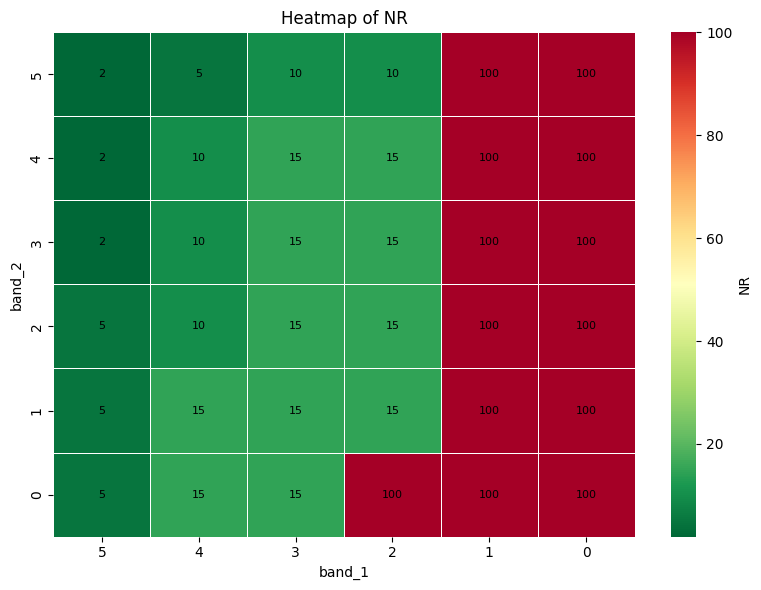

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_df = (
    running_gains_df
    .select("band_1", "band_2", "NR")
    .toPandas()
    .pivot(index="band_1", columns="band_2", values="NR")
    .sort_index(ascending=False)
    .sort_index(axis=1, ascending=False)
)

plt.figure(figsize=(max(8, heatmap_df.shape[1] * 0.8), max(6, heatmap_df.shape[0] * 0.65)))
ax = sns.heatmap(
    heatmap_df,
    mask=heatmap_df.isna(),
    cmap="RdYlGn_r",
    annot=False,
    linewidths=0.5,
    cbar_kws={"label": "NR"}
)

# Add labels ourselves so missing pivot combinations are shown as NULL.
for row_idx, (_, row) in enumerate(heatmap_df.iterrows()):
    for col_idx, value in enumerate(row):
        label = "NULL" if pd.isna(value) else f"{value:.0f}"
        ax.text(col_idx + 0.5, row_idx + 0.5, label,
                ha="center", va="center", fontsize=8, color="black")

plt.title("Heatmap of NR")
plt.xlabel("band_1")
plt.ylabel("band_2")
plt.tight_layout()
plt.show()

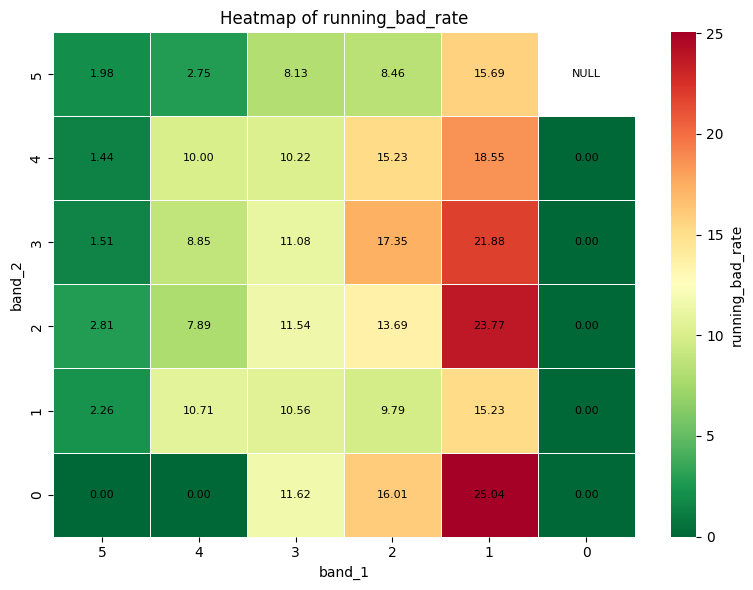

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_df = (
    running_gains_df
    .select("band_1", "band_2", "running_bad_rate")
    .toPandas()
    .pivot(index="band_1", columns="band_2", values="running_bad_rate")
    .sort_index(ascending=False)
    .sort_index(axis=1, ascending=False)
)

plt.figure(figsize=(max(8, heatmap_df.shape[1] * 0.8), max(6, heatmap_df.shape[0] * 0.65)))
ax = sns.heatmap(
    heatmap_df,
    mask=heatmap_df.isna(),
    cmap="RdYlGn_r",
    annot=False,
    linewidths=0.5,
    cbar_kws={"label": "running_bad_rate"}
)

# Add labels ourselves so missing pivot combinations are shown as NULL.
for row_idx, (_, row) in enumerate(heatmap_df.iterrows()):
    for col_idx, value in enumerate(row):
        label = "NULL" if pd.isna(value) else f"{value:.2f}"
        ax.text(col_idx + 0.5, row_idx + 0.5, label,
                ha="center", va="center", fontsize=8, color="black")

plt.title("Heatmap of running_bad_rate")
plt.xlabel("band_1")
plt.ylabel("band_2")
plt.tight_layout()
plt.show()